In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

In [4]:
data = pd.read_csv('diabetes_prediction_dataset.csv', sep=';')
data.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


In [5]:
#melihat informasi data
print("\nInformasi Dataset")
data.info()


Informasi Dataset
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB


In [6]:
#melihat informasi data
data.describe()

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,diabetes
count,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,41.885856,0.07485,0.039420,27.320767,5.527507,138.058060,0.085000
std,22.516840,0.26315,0.194593,6.636783,1.070672,40.708136,0.278883
min,0.080000,0.00000,0.000000,10.010000,3.500000,80.000000,0.000000
25%,24.000000,0.00000,0.000000,23.630000,4.800000,100.000000,0.000000
50%,43.000000,0.00000,0.000000,27.320000,5.800000,140.000000,0.000000
75%,60.000000,0.00000,0.000000,29.580000,6.200000,159.000000,0.000000
max,80.000000,1.00000,1.000000,95.690000,9.000000,300.000000,1.000000


In [7]:
#cek missing values
missing_values = data.isnull().sum()
missing_values

,0
gender,0
age,0
hypertension,0
heart_disease,0
smoking_history,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
diabetes,0


In [8]:
#Mengidentifikasi baris duplikat
duplicates = data.duplicated()

print("Baris duplikat:")
print(data[duplicates])

Baris duplikat:
       gender   age  hypertension  heart_disease smoking_history    bmi  \
2756     Male  80.0             0              0         No Info  27.32   
3272   Female  80.0             0              0         No Info  27.32   
3418   Female  19.0             0              0         No Info  27.32   
3939   Female  78.0             1              0          former  27.32   
3960     Male  47.0             0              0         No Info  27.32   
...       ...   ...           ...            ...             ...    ...   
99980  Female  52.0             0              0           never  27.32   
99985    Male  25.0             0              0         No Info  27.32   
99989  Female  26.0             0              0         No Info  27.32   
99990    Male  39.0             0              0         No Info  27.32   
99995  Female  80.0             0              0         No Info  27.32   

       HbA1c_level  blood_glucose_level  diabetes  
2756           6.6             

In [9]:
#menghapus baris duplikat
data = data.drop_duplicates()

print("DataFrame setelah menghapus duplikat")
print(data)

DataFrame setelah menghapus duplikat
       gender   age  hypertension  heart_disease smoking_history    bmi  \
0      Female  80.0             0              1           never  25.19   
1      Female  54.0             0              0         No Info  27.32   
2        Male  28.0             0              0           never  27.32   
3      Female  36.0             0              0         current  23.45   
4        Male  76.0             1              1         current  20.14   
...       ...   ...           ...            ...             ...    ...   
99994  Female  36.0             0              0         No Info  24.60   
99996  Female   2.0             0              0         No Info  17.37   
99997    Male  66.0             0              0          former  27.83   
99998  Female  24.0             0              0           never  35.42   
99999  Female  57.0             0              0         current  22.43   

       HbA1c_level  blood_glucose_level  diabetes  
0         

In [10]:
#hapus kolom HbA1c_level
data = data.drop(columns="HbA1c_level")
data.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,140,0
1,Female,54.0,0,0,No Info,27.32,80,0
2,Male,28.0,0,0,never,27.32,158,0
3,Female,36.0,0,0,current,23.45,155,0
4,Male,76.0,1,1,current,20.14,155,0


In [11]:
#melakukan feature encoding menggunakan LavelEncoder

#pilih kolom bertipe 'object'
categorical_cols = list(data.select_dtypes(include=['object']).columns)

encoders = {}

#loop melalui seiap kolom kategorikal
for column in categorical_cols:
  #buat instansiasi objek LabelEncoder
  label_encoder = LabelEncoder()

  #terapkan fit encodedr ke data dan sekaligus ubah data
  data[column] = label_encoder.fit_transform(data[column])

  #simpan encoder
  encoders[column] = label_encoder

#tampilkan 5 baris untuk verifikasi
data.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,blood_glucose_level,diabetes
0,0,80.0,0,1,4,25.19,140,0
1,0,54.0,0,0,0,27.32,80,0
2,1,28.0,0,0,4,27.32,158,0
3,0,36.0,0,0,1,23.45,155,0
4,1,76.0,1,1,1,20.14,155,0


In [12]:
columns = [
    'gender',
    'smoking_history',
]

for column in columns:
    print(f'\nMapping {column}:')

    encoder = encoders[column]

    for category, number in zip(
        encoder.classes_,
        encoder.transform(encoder.classes_)
    ):
        print(f'{category} -> {number}')


Mapping gender:
Female -> 0
Male -> 1
Other -> 2

Mapping smoking_history:
No Info -> 0
current -> 1
ever -> 2
former -> 3
never -> 4
not current -> 5


In [13]:
#memilih kolom numerik
numerical_cols = data.select_dtypes(include=['number']).columns

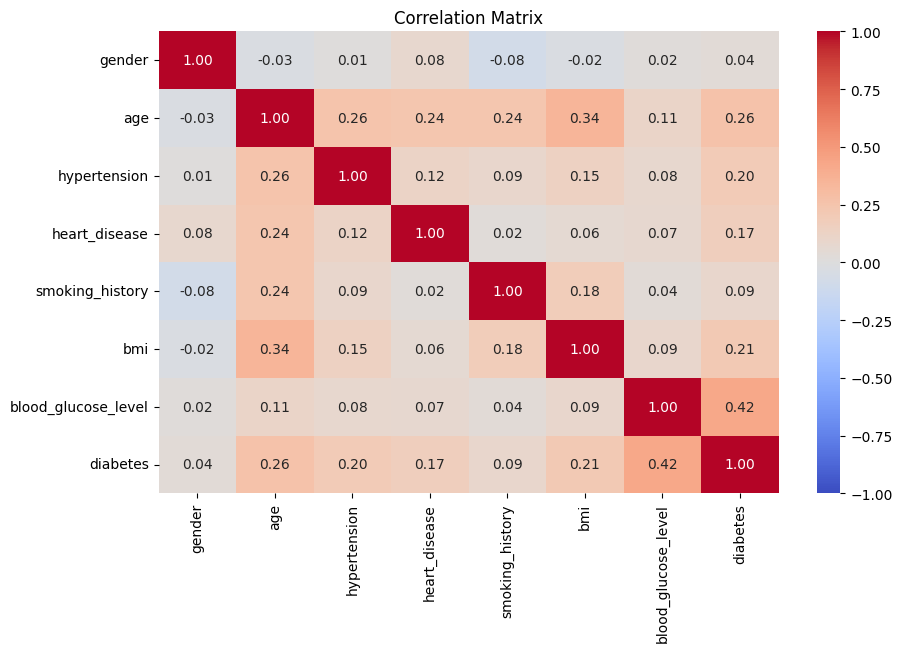

In [14]:
#menampilkan korelasi antar fitur

#hitung matriks korelasi
correlation = data[numerical_cols].corr()

#buat visualisasi heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(correlation,
            annot=True,
            cmap='coolwarm',
            fmt=".2f",
            vmin=-1,
            vmax=1)
plt.title('Correlation Matrix')
plt.show()

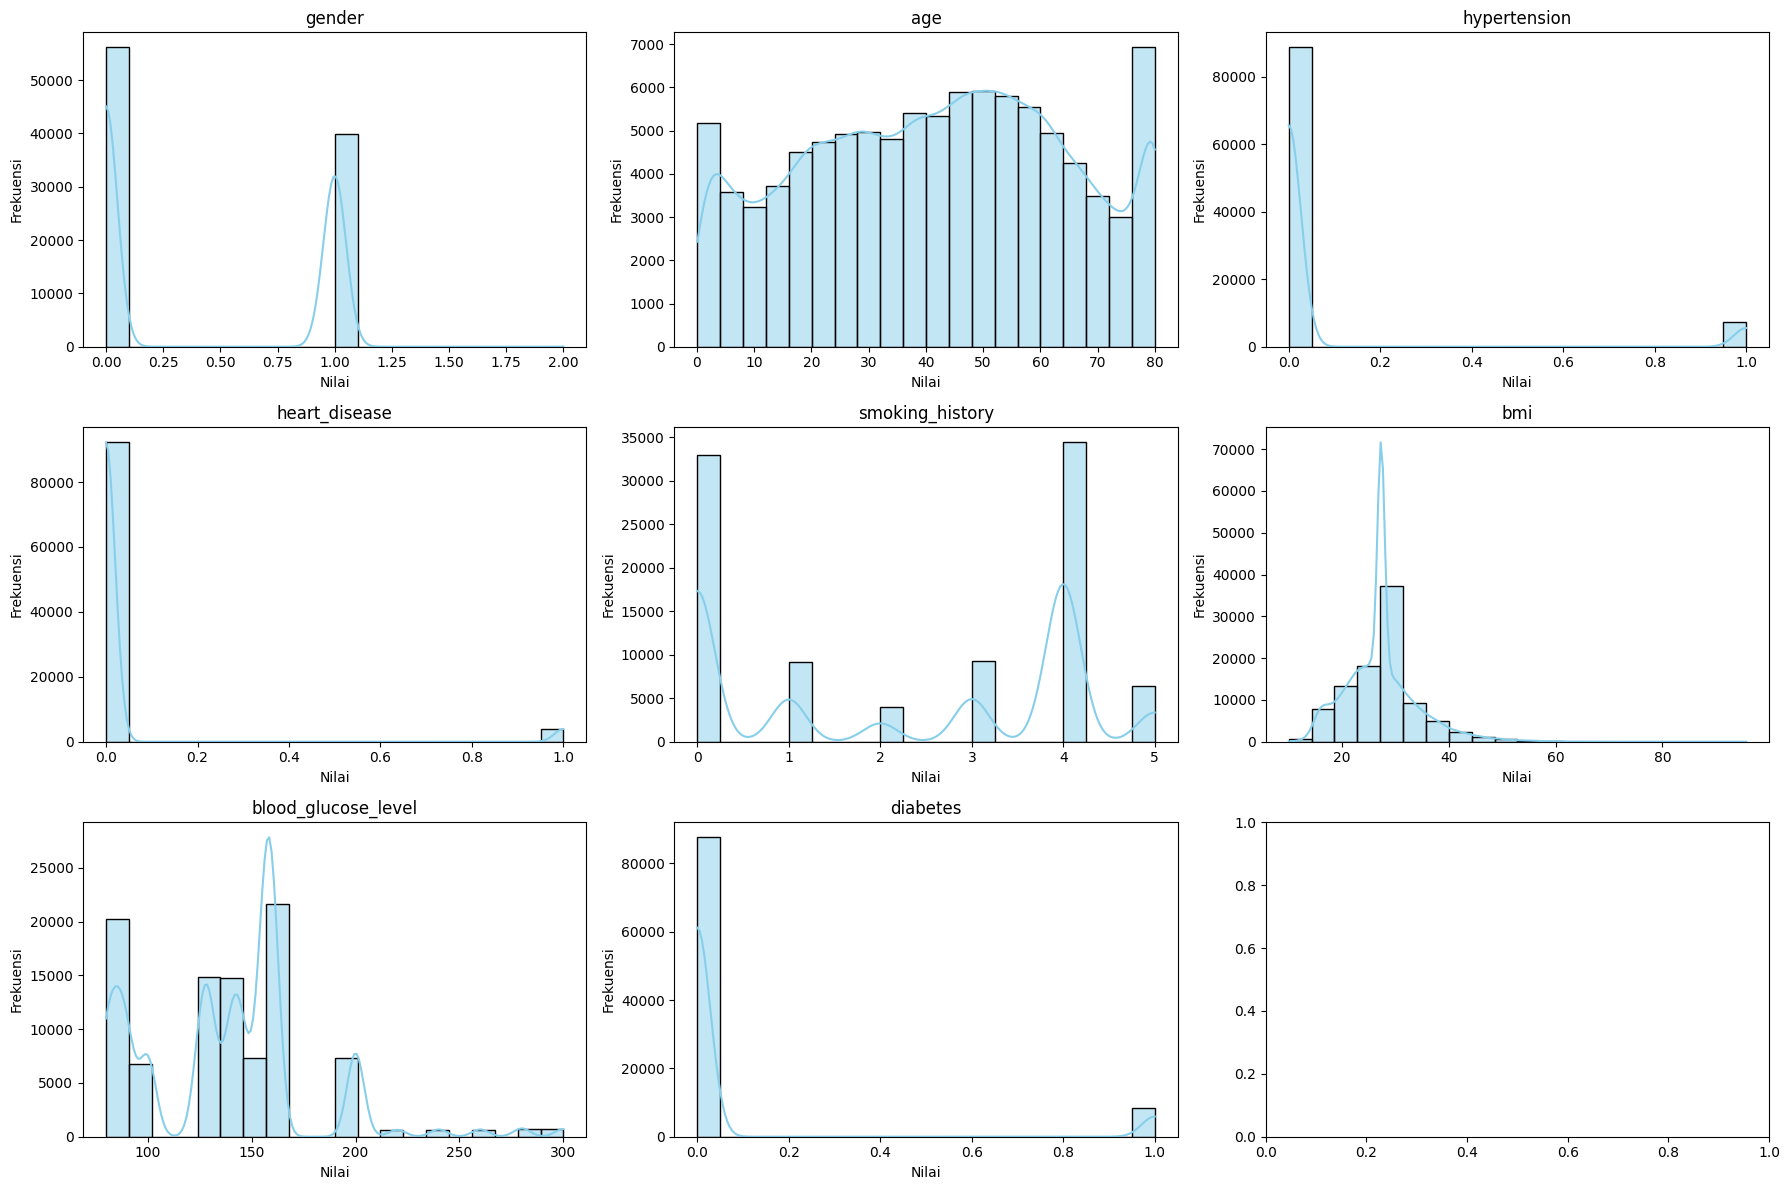

In [15]:
fig, axes = plt.subplots(3, 3, figsize=(18, 12))

axes = axes.flatten()

for i, column in enumerate(numerical_cols):
    sns.histplot(
        data[column],
        bins=20,
        kde=True,
        color='skyblue',
        ax=axes[i]
    )

    axes[i].set_title(column)
    axes[i].set_xlabel('Nilai')
    axes[i].set_ylabel('Frekuensi')

plt.tight_layout()
plt.show()

In [16]:
#data splitting

#pisahkan fitur (X) dan target (y)
X = data.drop(columns=['diabetes'])
y = data['diabetes']

#split data menjadi set pelatihhan dan set uji
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

#menghitung panjang/jumlah data
print("jumlah data: ", len(X))

#menghitung jumlah data pada x_train
print("jumlah data latih: ", len(X_train))

#menghitung jumlah data test
print("jumlah data test: ", len(X_test))

jumlah data:  96146
jumlah data latih:  76916
jumlah data test:  19230


In [17]:
#pelatihan model

knn = KNeighborsClassifier(n_neighbors=5).fit(X_train, y_train)
print('Model training selesai')

Model training selesai


In [18]:
#evaluasi model
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

y_pred = knn.predict(X_test)
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

results = {
      'Confusion Matrix': cm,
      'True Positive (TP)': tp,
      'False Positive (FP)': fp,
      'False Negative (FN)': fn,
      'True Negative (TN)': tn,
      'Accuracy': accuracy_score(y_test, y_pred),
      'Precision': precision_score(y_test, y_pred),
      'Recall': recall_score(y_test, y_pred),
      'F1-Score': f1_score(y_test, y_pred)
  }

for key, value in results.items():
    print(f"{key}:")
    print(value)
    print()

Confusion Matrix:
[[17307   202]
 [  939   782]]

True Positive (TP):
782

False Positive (FP):
202

False Negative (FN):
939

True Negative (TN):
17307

Accuracy:
0.940665626625065

Precision:
0.7947154471544715

Recall:
0.4543869843114468

F1-Score:
0.57818853974122



In [19]:
import joblib

joblib.dump(knn, 'knn_diabetes.pkl')

['knn_diabetes.pkl']